In [10]:
import os
import re

# Directorio que contiene las carpetas con los archivos best_results.txt
directorio_principal = "RESULTADOS ESTUDIO MOSAIC"

# Lista para almacenar los valores de "Value" y los parámetros de "Params" de cada archivo


resultados = {}
# Función para leer los archivos best_results.txt y extraer los valores y parámetros
def leer_best_results(archivo, carpeta):
    valores = []
    parametros = []
    with open(archivo, 'r') as f:
        
        leer = False
        value = None
        params = None
        primera = True
        for linea in f:
            
            if leer:
                if linea.strip().startswith('Value:'):
                    
                    value = None
                    if(not primera):
                        parametros.append(params)
                    params = None
                    value = [float(x) for x in re.findall(r"[-+]?\d*\.\d+|\d+", linea)]
                    if value:
                        valores.append(value)
                    
                    
                elif linea.strip().startswith('Params:'):
                    
                    primera = False
                    params = {}
                    
                elif linea.strip():
                    
                    param, valor = linea.strip().split(': ')
                    
                    
                    params[param] = valor

                    
                    
                
                   
                
                
            
            elif linea.strip().startswith('Best trial:'):
                leer = True
    
    parametros.append(params)
    resultados[carpeta] = (valores.copy(), parametros.copy())  

        

# Iterar sobre las carpetas y leer los archivos best_results.txt dentro de ellas
for carpeta in os.listdir(directorio_principal):
    ruta_carpeta = os.path.join(directorio_principal, carpeta)

    archivo_best_results = os.path.join(ruta_carpeta, 'best_results.txt')
   
    if os.path.isfile(archivo_best_results):
        leer_best_results(archivo_best_results, carpeta)

# Imprimir los valores y parámetros obtenidos
print(resultados)


{'estudio_adam': ([[0.9333333373069763, 0.8999999761581421, 0.9600000381469727, 0.054433102150715826, 0.12247449159622192, 0.07999999821186066], [0.8388888955116272, 0.75, 0.8999999761581421, 0.06186404907062873, 0.0, 0.12247449159622192], [0.8861111164093017, 0.800000011920929, 0.9600000381469727, 0.005555558204650879, 0.10000000149011612, 0.07999999821186066], [0.9305555582046509, 0.8500000238418579, 1.0, 0.05692750231639192, 0.12247449159622192, 0.0], [0.8638888955116272, 0.8500000238418579, 0.8700000047683716, 0.04339027300941767, 0.12247449159622192, 0.107703298330307]], [{'batch_size': '5', 'lr': '8.324546221005873e-05', 'data_aug': 'False', 'ini': 'G', 'e_all': '45'}, {'batch_size': '5', 'lr': '3.325636688149855e-05', 'data_aug': 'True', 'ini': 'None', 'e_all': '45'}, {'batch_size': '5', 'lr': '6.12648937474318e-05', 'data_aug': 'True', 'ini': 'O', 'e_all': '42'}, {'batch_size': '5', 'lr': '9.734422735457594e-05', 'data_aug': 'True', 'ini': 'None', 'e_all': '40'}, {'batch_size':

In [15]:
import pandas as pd

# Nuevo diccionario para almacenar los DataFrames
dataframes = {}

# Nombres de las columnas para los DataFrames
columns = ['accuracy', 'recall', 'precision', 'std_accuracy', 'std_recall', 'std_precision']

# Convertir cada lista de listas en un DataFrame
for key, value in resultados.items():
    df = pd.DataFrame(value[0], columns=columns)
    # Calcular media de las desviaciones estándar
    df['mean_std'] = df[['std_accuracy', 'std_recall', 'std_precision']].mean(axis=1)
    # Calcular F1-score
    df['f1_score'] = 2 * (df['precision'] * df['recall']) / (df['precision'] + df['recall'])

    # Calcular media de F1-score y accuracy
    df['mean_f1_accuracy'] = df[['f1_score', 'accuracy']].mean(axis=1)
    
    # Guardar el DataFrame y el metadato en el diccionario
    dataframes[key] = [df, value[1]]

for key, df_info in dataframes.items():
    if(key == 'estudio_tl_sgd'):
        df = df_info[0]

        # Mejor fila en términos de la media de accuracy y f1_score
        best_f1_accuracy_idx = df['mean_f1_accuracy'].idxmax()
        best_f1_accuracy_row = df.loc[best_f1_accuracy_idx]

        # Mejor fila en términos de la media del std
        best_std_idx = df['mean_std'].idxmin()
        best_std_row = df.loc[best_std_idx]

        # print(df_info[1][best_f1_accuracy_idx])
        # print(best_f1_accuracy_row)
        print(df_info[1][best_std_idx])
        print(best_std_row)

# Mostrar los DataFrames para verificar
for key, df in dataframes.items():
    print(f"DataFrame for {key}:")
    print(df)
    print("\n")


{'batch_size': '5', 'lr': '0.0010020371119832776', 'data_aug': 'True', 'ini': 'G', 'e_freeze': '6', 'e_all': '47'}
accuracy            0.930556
recall              0.850000
precision           1.000000
std_accuracy        0.056928
std_recall          0.122474
std_precision       0.000000
mean_std            0.059801
f1_score            0.918919
mean_f1_accuracy    0.924737
Name: 7, dtype: float64
DataFrame for estudio_adam:
[   accuracy  recall  precision  std_accuracy  std_recall  std_precision  \
0  0.933333    0.90       0.96      0.054433    0.122474       0.080000   
1  0.838889    0.75       0.90      0.061864    0.000000       0.122474   
2  0.886111    0.80       0.96      0.005556    0.100000       0.080000   
3  0.930556    0.85       1.00      0.056928    0.122474       0.000000   
4  0.863889    0.85       0.87      0.043390    0.122474       0.107703   

   mean_std  f1_score  mean_f1_accuracy  
0  0.085636  0.929032          0.931183  
1  0.061446  0.818182          0.828

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Crear un DataFrame para comparar todos los modelos
summary_stats = []

for key, (df, params) in dataframes.items():
    # Calcular estadísticas
    stats = {
        'model': key,
        'max_accuracy': df['accuracy'].max(),
        'max_recall': df['recall'].max(),
        'max_precision': df['precision'].max(),

        'min_std_accuracy': df['std_accuracy'].min(),
        'min_std_recall': df['std_recall'].min(),
        'min_std_precision': df['std_precision'].min(),
        
        'mean_accuracy': df['accuracy'].mean(),
        'mean_recall': df['recall'].mean(),
        'mean_precision': df['precision'].mean(),

        'mean_std_accuracy': df['std_accuracy'].mean(),
        'mean_std_recall': df['std_recall'].mean(),
        'mean_std_precision': df['std_precision'].mean(),
        #**params
    }
    summary_stats.append(stats)

# Convertir la lista de diccionarios en un DataFrame
summary_df = pd.DataFrame(summary_stats)
print(summary_df)
# Mostrar el DataFrame resumido
# print(summary_df)

# # # Mostrar estadísticas interesantes para la toma de decisiones
# # print("\nMejores Modelos Basados en Diferentes Métricas:")
# # print("Modelo con la mejor precisión media:")
# # print(summary_df.loc[summary_df['mean_precision'].idxmax()])

# # print("\nModelo con la mejor exactitud media:")
# # print(summary_df.loc[summary_df['mean_accuracy'].idxmax()])

# # print("\nModelo con el mejor recall medio:")
# # print(summary_df.loc[summary_df['mean_recall'].idxmax()])

# # # Mostrar estadísticas interesantes para la toma de decisiones
# # print("\nMejores Modelos Basados en Diferentes Métricas:")
# # print("Modelo con la mejor std precision")
# # print(summary_df.loc[summary_df['std_precision'].idxmin()])

# # print("\nModelo con la mejor std accuracy:")
# # print(summary_df.loc[summary_df['std_accuracy'].idxmin()])

# # print("\nModelo con la mejor std recall:")
# # print(summary_df.loc[summary_df['std_recall'].idxmin()])

import plotly.graph_objects as go
import numpy as np
categories = ['Max Accuracy', 'Max Recall', 'Max Precision', 'Mean Accuracy', 'Mean Recall', 'Mean Precision']

##radar charts para las métricas
fig = go.Figure()
fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][1:4] ,summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][7:10])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][0],
    


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_oc_rms'].values[0][1:4] ,summary_df.loc[summary_df['model'] == 'estudio2_oc_rms'].values[0][7:10])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_oc_rms'].values[0][0],
    


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][1:4] ,summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][7:10])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][0],
    


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][1:4] ,summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][7:10])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][0],
    


))

fig.update_layout(
    polar = dict(
        radialaxis = dict(
            visible = True,
            range=[0.6,1] #se ajusta el rango
        )
    ),
    width = 1500,
    height = 1000,
    title = 'COMPARATIVA FORMAS DE ENTRENAR 4 IMÁGENES MÉTRICAS',
    
    font=dict(
        size=26
    )
        

   
    

)
fig.show()

                  model  max_accuracy  max_recall  max_precision  \
0         estudio2_adam        0.8750       0.900       1.000000   
1      estudio2_oc_adam        0.8750       0.825       0.975000   
2       estudio2_oc_rms        0.8875       0.875       1.000000   
3       estudio2_oc_sgd        0.8875       0.925       0.971429   
4          estudio2_rms        0.8750       0.850       1.000000   
5          estudio2_sgd        0.8750       0.875       1.000000   
6      estudio2_tl_adam        0.9000       0.825       1.000000   
7   estudio2_tl_oc_adam        0.8500       0.800       0.966667   
8    estudio2_tl_oc_rms        0.8750       0.850       0.971429   
9    estudio2_tl_oc_sgd        0.8000       0.750       0.971429   
10      estudio2_tl_rms        0.8750       0.875       1.000000   
11      estudio2_tl_sgd        0.8875       0.875       0.971429   

    min_std_accuracy  min_std_recall  min_std_precision  mean_accuracy  \
0              0.025        0.050000     

In [11]:
import plotly.graph_objects as go
import numpy as np
categories = ['Min STD Accuracy', 'Min STD Recall', 'Min STD Precision', 'Mean STD Accuracy', 'Mean STD Recall', 'Mean STD Precision']

##radar charts para las desviaciones
fig = go.Figure()
fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][4:7] ,summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][10:13])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_sgd'].values[0][0]


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_oc_sgd'].values[0][4:7] ,summary_df.loc[summary_df['model'] == 'estudio2_oc_sgd'].values[0][10:13])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_oc_sgd'].values[0][0]


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][4:7] ,summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][10:13])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_tl_rms'].values[0][0]


))

fig.add_trace(go.Scatterpolar(
    r = np.concatenate((summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][4:7] ,summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][10:13])),
    theta = categories,
    name = summary_df.loc[summary_df['model'] == 'estudio2_tl_oc_rms'].values[0][0]


))

fig.update_layout(
    polar = dict(
        radialaxis = dict(
            visible = True,
            range=[0,0.2] ##se ajusta el rango para que se vea mejor
        )
    ),
    width = 1500,
    height = 1000,
    title = 'COMPARATIVA FORMAS DE ENTRENAR 4 IMÁGENES STD',
    font=dict(
        size=22
    )

)
fig.show()

estudio_adam
estudio_rms
estudio_sgd


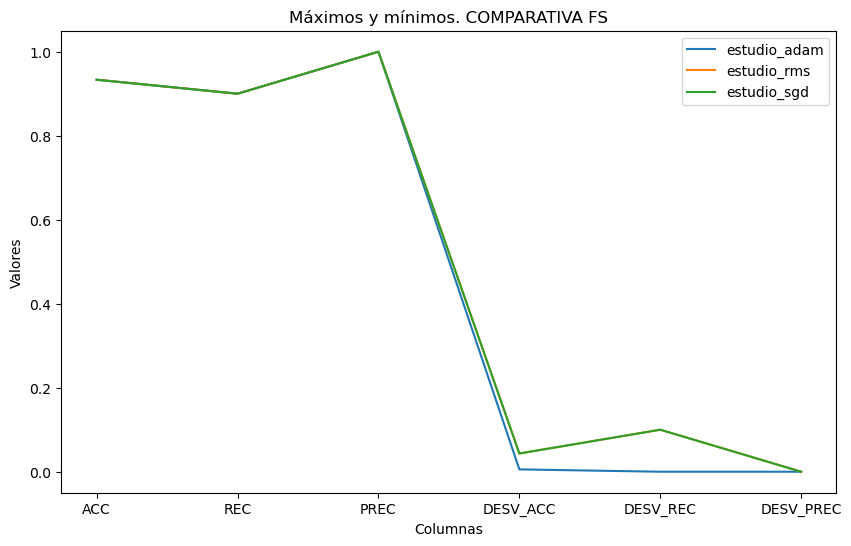

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import re

plt.figure(figsize=(10, 6))
for carpeta in os.listdir(directorio_principal):
    
    if re.match('(?!.*tl)(?!.*oc).*.*', carpeta): #
        print(carpeta)
        df = pd.DataFrame(resultados[carpeta][0], columns=['ACC', 'REC', 'PREC', 'DESV_ACC', 'DESV_REC', 'DESV_PREC'])
        # Graficar cada columna como un punto con cinco etiquetas en el eje x
        maximos = df.iloc[:, :3].max()
        minimos = df.iloc[:, -3:].min()

        concat = pd.concat((maximos, minimos))
        
        ejex = range(0,len(df.columns))
        plt.plot(ejex, concat, label=carpeta)

plt.xticks(range(len(df.columns)), df.columns)
plt.xlabel('Columnas')
plt.ylabel('Valores')
plt.title('Máximos y mínimos. COMPARATIVA FS')
plt.legend()
plt.show()